Import Libraries

In [ ]:
# Cell 1: Import all necessary libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, StandardScaler
import io
from google.colab import files

# Set style for plots
sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


Load the Raw Dataset

In [ ]:


uploaded = files.upload()

# Get the actual filename that Colab saved (the first key in the dict)
actual_filename = list(uploaded.keys())[0]
print("Actual filename:", actual_filename)

# Read the file using BytesIO
df = pd.read_csv(io.BytesIO(uploaded[actual_filename]))

print("Dataset loaded. Shape:", df.shape)

Saving ObesityDataSet_raw_and_data_sinthetic.csv to ObesityDataSet_raw_and_data_sinthetic.csv
Actual filename: ObesityDataSet_raw_and_data_sinthetic.csv
Dataset loaded. Shape: (2111, 17)


Show Summary Statistics

In [ ]:
# Show structural integrity and check for null values
print("=== Dataset Info ===")
display(df.info())

# Show the first 5 rows
print("\n=== First 5 Rows (Transposed) ===")
display(df.head().T)

# Generate statistical summary of numerical features
print("\n=== Statistical Summary of Numerical Features ===")
display(df.describe())

=== Dataset Info ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2111 entries, 0 to 2110
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Gender                          2111 non-null   object 
 1   Age                             2111 non-null   float64
 2   Height                          2111 non-null   float64
 3   Weight                          2111 non-null   float64
 4   family_history_with_overweight  2111 non-null   object 
 5   FAVC                            2111 non-null   object 
 6   FCVC                            2111 non-null   float64
 7   NCP                             2111 non-null   float64
 8   CAEC                            2111 non-null   object 
 9   SMOKE                           2111 non-null   object 
 10  CH2O                            2111 non-null   float64
 11  SCC                             2111 non-null   object 
 12  FAF          

None


=== First 5 Rows (Transposed) ===


,0,1,2,3,4
Gender,Female,Female,Male,Male,Male
Age,21.0,21.0,23.0,27.0,22.0
Height,1.62,1.52,1.8,1.8,1.78
Weight,64.0,56.0,77.0,87.0,89.8
family_history_with_overweight,yes,yes,yes,no,no
FAVC,no,no,no,no,no
FCVC,2.0,3.0,2.0,3.0,2.0
NCP,3.0,3.0,3.0,3.0,1.0
CAEC,Sometimes,Sometimes,Sometimes,Sometimes,Sometimes
SMOKE,no,yes,no,no,no



=== Statistical Summary of Numerical Features ===


,Age,Height,Weight,FCVC,NCP,CH2O,FAF,TUE
count,2111.000000,2111.000000,2111.000000,2111.000000,2111.000000,2111.000000,2111.000000,2111.000000
mean,24.312600,1.701677,86.586058,2.419043,2.685628,2.008011,1.010298,0.657866
std,6.345968,0.093305,26.191172,0.533927,0.778039,0.612953,0.850592,0.608927
min,14.000000,1.450000,39.000000,1.000000,1.000000,1.000000,0.000000,0.000000
25%,19.947192,1.630000,65.473343,2.000000,2.658738,1.584812,0.124505,0.000000
50%,22.777890,1.700499,83.000000,2.385502,3.000000,2.000000,1.000000,0.625350
75%,26.000000,1.768464,107.430682,3.000000,3.000000,2.477420,1.666678,1.000000
max,61.000000,1.980000,173.000000,3.000000,4.000000,3.000000,3.000000,2.000000


Visualize Using Original Data

/tmp/ipykernel_1897/2389689168.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, y='NObeyesdad', order=df['NObeyesdad'].value_counts().index, palette='viridis')


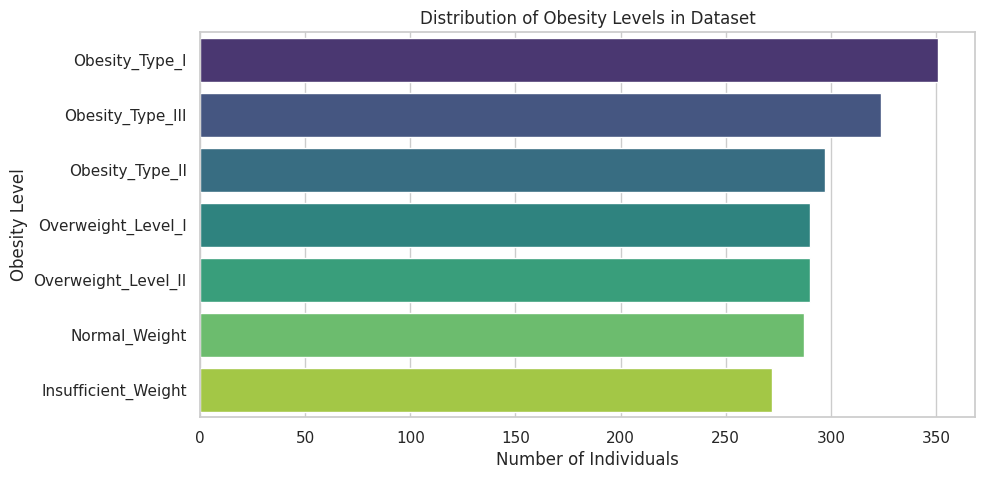

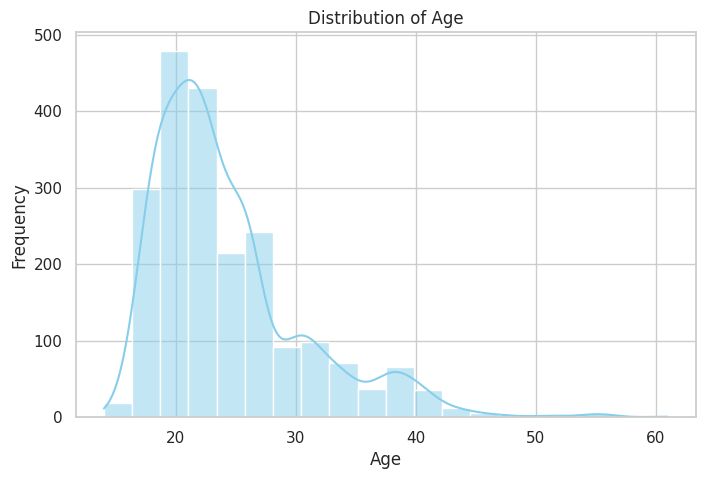

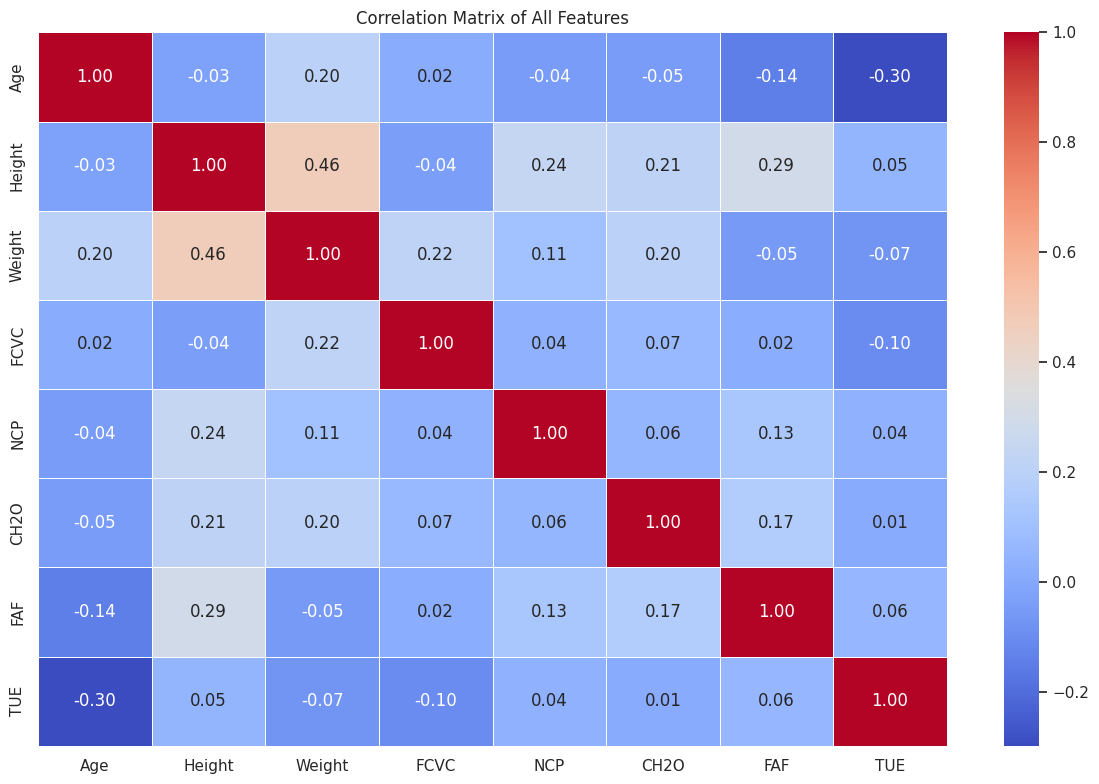

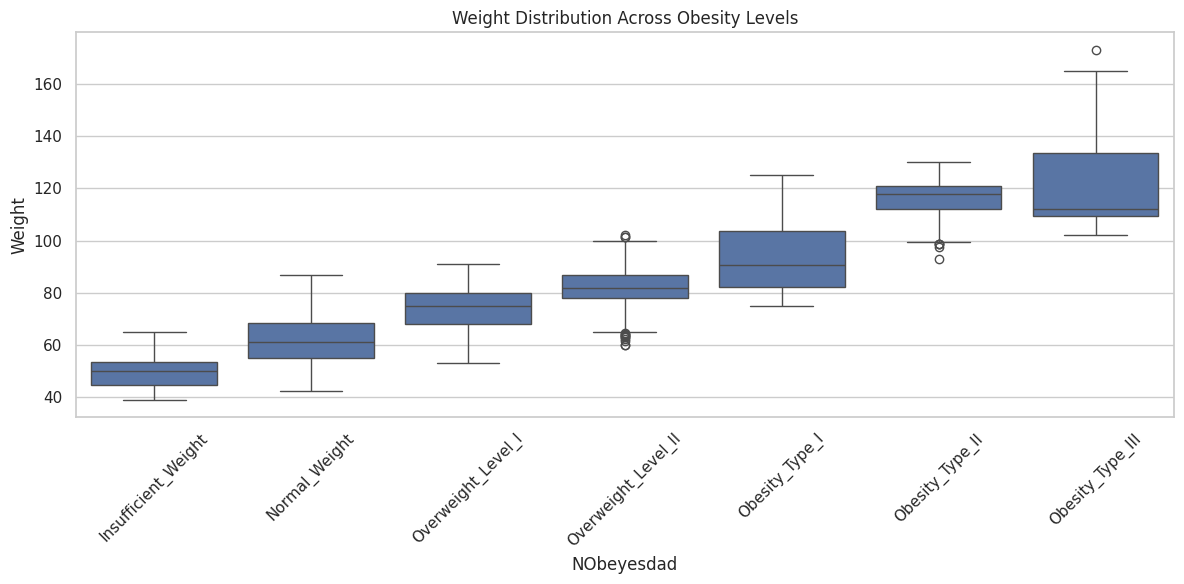

In [ ]:


# Set the style for the plots
sns.set_theme(style="whitegrid")

# 1. Bar Chart for the Target Variable (NObeyesdad)
plt.figure(figsize=(10, 5))
sns.countplot(data=df, y='NObeyesdad', order=df['NObeyesdad'].value_counts().index, palette='viridis')
plt.title('Distribution of Obesity Levels in Dataset')
plt.xlabel('Number of Individuals')
plt.ylabel('Obesity Level')
plt.show()

# 2. Histogram for Age (From Chapter 3 notes)
plt.figure(figsize=(8, 5))
sns.histplot(df['Age'], bins=20, kde=True, color='skyblue')
plt.title('Distribution of Age')
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.show()


# ===== CORRELATION HEATMAP =====
plt.figure(figsize=(12, 8))
# Select only numeric columns (after encoding, before scaling is fine)
numeric_df = df.select_dtypes(include=[np.number])
correlation_matrix = numeric_df.corr()
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Matrix of All Features')
plt.tight_layout()
plt.show()


# ===== BOXPLOT: WEIGHT BY OBESITY LEVEL =====
obesity_order = [
    'Insufficient_Weight',
    'Normal_Weight',
    'Overweight_Level_I',
    'Overweight_Level_II',
    'Obesity_Type_I',
    'Obesity_Type_II',
    'Obesity_Type_III'
]
plt.figure(figsize=(12, 6))
# Use original data for meaningful weight values (kg), not scaled
sns.boxplot(x='NObeyesdad', y='Weight', data=df, order=obesity_order)
plt.xticks(rotation=45)
plt.title('Weight Distribution Across Obesity Levels')
plt.tight_layout()
plt.show()

Duplicate Removal

In [ ]:
#Data Cleaning: Check and remove duplicates
print("Duplicates before cleaning:", df.duplicated().sum())
df = df.drop_duplicates()
print("Duplicates after cleaning:", df.duplicated().sum())
print("New dataset shape:", df.shape)

Duplicates before cleaning: 24
Duplicates after cleaning: 0
New dataset shape: (2087, 17)


Column Header Standardization

In [ ]:
# Standardize column names
df.columns = df.columns.str.lower().str.replace(' ', '_')
print("Standardized columns:", df.columns.tolist())

Standardized columns: ['gender', 'age', 'height', 'weight', 'family_history_with_overweight', 'favc', 'fcvc', 'ncp', 'caec', 'smoke', 'ch2o', 'scc', 'faf', 'tue', 'calc', 'mtrans', 'nobeyesdad']


Boxplot Analysis

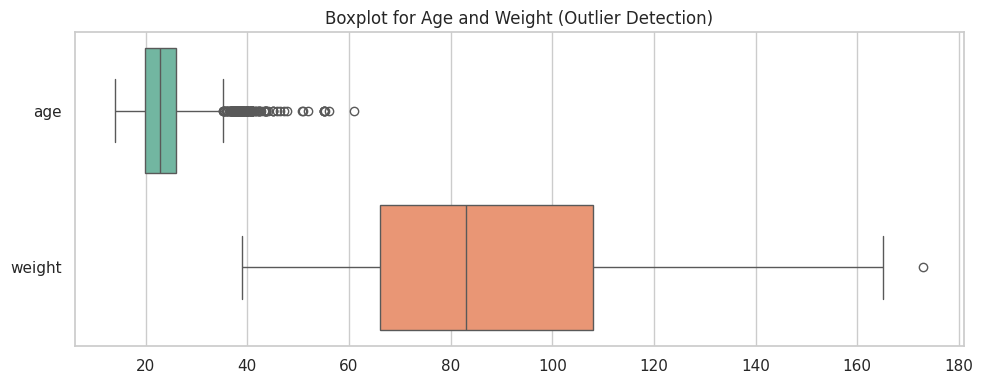

In [ ]:
# Generate boxplots for outlier detection
plt.figure(figsize=(10, 4))
sns.boxplot(data=df[['age', 'weight']], orient='h', palette='Set2')
plt.title('Boxplot for Age and Weight (Outlier Detection)')
plt.tight_layout()
plt.show()

Statistical Quantification of Outliers

In [ ]:
# Calculate bounds and outlier counts
Q1_age, Q3_age = df['age'].quantile(0.25), df['age'].quantile(0.75)
IQR_age = Q3_age - Q1_age
upper_age = Q3_age + 1.5 * IQR_age
age_outliers = df[df['age'] > upper_age].shape[0]

Q1_weight, Q3_weight = df['weight'].quantile(0.25), df['weight'].quantile(0.75)
IQR_weight = Q3_weight - Q1_weight
upper_weight = Q3_weight + 1.5 * IQR_weight
weight_outliers = df[df['weight'] > upper_weight].shape[0]

print(f"Age upper bound: {upper_age:.1f} years")
print(f"Number of age outliers: {age_outliers}")
print(f"Weight upper bound: {upper_weight:.1f} kg")
print(f"Number of weight outliers: {weight_outliers}")

Age upper bound: 35.1 years
Number of age outliers: 167
Weight upper bound: 171.0 kg
Number of weight outliers: 1


Label Encoding for Binary Features

In [ ]:
from sklearn.preprocessing import LabelEncoder

# Binary features (use lowercase names after standardization)
binary_features = ['gender', 'family_history_with_overweight', 'favc', 'smoke', 'scc']

le = LabelEncoder()
for col in binary_features:
    df[col] = le.fit_transform(df[col])

print("Binary encoding completed for:", binary_features)
print("Sample of encoded data:")
print(df[binary_features].head())


Binary encoding completed for: ['gender', 'family_history_with_overweight', 'favc', 'smoke', 'scc']
Sample of encoded data:
   gender  family_history_with_overweight  favc  smoke  scc
0       0                               1     0      0    0
1       0                               1     0      1    1
2       1                               1     0      0    0
3       1                               0     0      0    0
4       1                               0     0      0    0


Ordinal Encoding for Hierarchical Variables

In [ ]:
# Check unique values first to ensure correct mapping (lowercase names)
print("Unique CAEC values:", df['caec'].unique())
print("Unique CALC values:", df['calc'].unique())

# Ordinal mappings
caec_mapping = {'no': 0, 'Sometimes': 1, 'Frequently': 2, 'Always': 3}
calc_mapping = {'no': 0, 'Sometimes': 1, 'Frequently': 2, 'Always': 3}

df['caec'] = df['caec'].map(caec_mapping)
df['calc'] = df['calc'].map(calc_mapping)

print("\nCAEC mapping:", caec_mapping)
print("CALC mapping:", calc_mapping)

Unique CAEC values: ['Sometimes' 'Frequently' 'Always' 'no']
Unique CALC values: ['no' 'Sometimes' 'Frequently' 'Always']

CAEC mapping: {'no': 0, 'Sometimes': 1, 'Frequently': 2, 'Always': 3}
CALC mapping: {'no': 0, 'Sometimes': 1, 'Frequently': 2, 'Always': 3}


One-Hot Encoding for Nominal Feature

In [ ]:
# One-hot encoding for MTRANS
df = pd.get_dummies(df, columns=['mtrans'], prefix='MTRANS')
print("Columns after one-hot encoding:")
print([col for col in df.columns if 'MTRANS' in col])

Columns after one-hot encoding:
['MTRANS_Automobile', 'MTRANS_Bike', 'MTRANS_Motorbike', 'MTRANS_Public_Transportation', 'MTRANS_Walking']


Target Variable Encoding

In [ ]:
# Encode target variable
target_le = LabelEncoder()
df['nobeyesdad'] = target_le.fit_transform(df['nobeyesdad'])

# Store mapping for reference
target_mapping = dict(zip(target_le.classes_, target_le.transform(target_le.classes_)))
print("Target variable mapping:")
for category, code in target_mapping.items():
    print(f"  {code}: {category}")

Target variable mapping:
  0: Insufficient_Weight
  1: Normal_Weight
  2: Obesity_Type_I
  3: Obesity_Type_II
  4: Obesity_Type_III
  5: Overweight_Level_I
  6: Overweight_Level_II


Implementation of StandardScaler

In [ ]:
from sklearn.preprocessing import StandardScaler

# Identify continuous features for scaling
continuous_features = ['age', 'height', 'weight', 'fcvc', 'ncp', 'ch2o', 'faf', 'tue']

# Initialize and apply StandardScaler
scaler = StandardScaler()
df[continuous_features] = scaler.fit_transform(df[continuous_features])

print("Feature scaling completed.")
print("Features scaled:", continuous_features)
print("\nFirst 5 rows after scaling (first 4 features shown):")
print(df[continuous_features].head())

Feature scaling completed.
Features scaled: ['age', 'height', 'weight', 'fcvc', 'ncp', 'ch2o', 'faf', 'tue']

First 5 rows after scaling (first 4 features shown):
        age    height    weight      fcvc       ncp      ch2o       faf  \
0 -0.526613 -0.887408 -0.872985 -0.788364  0.390906 -0.007810 -1.186977   
1 -0.526613 -1.960788 -1.178508  1.082164  0.390906  1.636552  2.328908   
2 -0.212507  1.044677 -0.376509 -0.788364  0.390906 -0.007810  1.156947   
3  0.415705  1.044677  0.005395  1.082164  0.390906 -0.007810  1.156947   
4 -0.369560  0.830001  0.112328 -0.788364 -2.225418 -0.007810 -1.186977   

        tue  
0  0.554211  
1 -1.090505  
2  0.554211  
3 -1.090505  
4 -1.090505  


Final Prepared Dataset

In [ ]:
# Display the first 5 rows of the fully prepared dataset
# Use .head() to show the first 5 rows; transposing (.T) makes it easier to read if many columns
print("First 5 rows of the fully prepared dataset (transposed):")
print(df.head().T)


First 5 rows of the fully prepared dataset (transposed):
                                       0         1         2         3  \
gender                                 0         0         1         1   
age                            -0.526613 -0.526613 -0.212507  0.415705   
height                         -0.887408 -1.960788  1.044677  1.044677   
weight                         -0.872985 -1.178508 -0.376509  0.005395   
family_history_with_overweight         1         1         1         0   
favc                                   0         0         0         0   
fcvc                           -0.788364  1.082164 -0.788364  1.082164   
ncp                             0.390906  0.390906  0.390906  0.390906   
caec                                   1         1         1         1   
smoke                                  0         1         0         0   
ch2o                            -0.00781  1.636552  -0.00781  -0.00781   
scc                                    0         1     

Train Test Split

In [ ]:
from sklearn.model_selection import train_test_split

# Define features (X) and target (y) - using lowercase column names
X = df.drop('nobeyesdad', axis=1)
y = df['nobeyesdad']

# Split the data: 80% training, 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,           # 20% for testing
    random_state=42,         # Ensures reproducible results
    stratify=y               # Maintains class distribution
)

print(f"Training set size: {X_train.shape}")
print(f"Testing set size: {X_test.shape}")

Training set size: (1669, 20)
Testing set size: (418, 20)


Manual Tuning Logistic Regression Hyperparameter (max_iter)

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

for max_iter in [100, 200, 500, 1000]:
    lr = LogisticRegression(max_iter=max_iter, random_state=42)
    lr.fit(X_train, y_train)
    acc = accuracy_score(y_test, lr.predict(X_test))
    print(f"max_iter={max_iter}: Test Accuracy={acc:.4f}")

max_iter=100: Test Accuracy=0.8852
max_iter=200: Test Accuracy=0.8852
max_iter=500: Test Accuracy=0.8852
max_iter=1000: Test Accuracy=0.8852


Logistic Regression Model Training

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

#Value that gave highest accuracy
best_max_iter = 100

# Initialize and train the model
logreg_model = LogisticRegression(max_iter=best_max_iter, random_state=42)
logreg_model.fit(X_train, y_train)

# Make predictions on training and testing sets
y_train_pred_logreg = logreg_model.predict(X_train)
y_test_pred_logreg = logreg_model.predict(X_test)

# Calculate accuracy
train_accuracy = accuracy_score(y_train, y_train_pred_logreg)
test_accuracy = accuracy_score(y_test, y_test_pred_logreg)

print(f"Logistic Regression - Training Accuracy: {train_accuracy:.4f}")
print(f"Logistic Regression - Testing Accuracy: {test_accuracy:.4f}")

Logistic Regression - Training Accuracy: 0.9017
Logistic Regression - Testing Accuracy: 0.8852


Manual Tuning Decision Tree Hyperparameter (max_depth)

In [ ]:
from sklearn.tree import DecisionTreeClassifier

for max_depth in [3, 5, 10, None]:
    dt = DecisionTreeClassifier(max_depth=max_depth, random_state=42)
    dt.fit(X_train, y_train)
    acc = accuracy_score(y_test, dt.predict(X_test))
    print(f"max_depth={max_depth}: Test Accuracy={acc:.4f}")

max_depth=3: Test Accuracy=0.6531
max_depth=5: Test Accuracy=0.8325
max_depth=10: Test Accuracy=0.9354
max_depth=None: Test Accuracy=0.9378


Decision Tree Model Training

In [ ]:
from sklearn.tree import DecisionTreeClassifier

# Choose the best max_depth (e.g., 5 if it gave highest test accuracy)
best_max_depth = 10   # change based on tuning output
dt_model = DecisionTreeClassifier(max_depth=best_max_depth, random_state=42)
dt_model.fit(X_train, y_train)

y_train_pred = dt_model.predict(X_train)
y_test_pred = dt_model.predict(X_test)

print(f"Decision Tree - Training Accuracy: {accuracy_score(y_train, y_train_pred):.4f}")
print(f"Decision Tree - Testing Accuracy:  {accuracy_score(y_test, y_test_pred):.4f}")

Decision Tree - Training Accuracy: 0.9952
Decision Tree - Testing Accuracy:  0.9354


In [ ]:
X_test

,gender,age,height,weight,family_history_with_overweight,favc,fcvc,ncp,caec,smoke,ch2o,scc,faf,tue,calc,MTRANS_Automobile,MTRANS_Bike,MTRANS_Motorbike,MTRANS_Public_Transportation,MTRANS_Walking
1177,0,-0.690693,-1.219082,-0.540208,1,0,1.082164,1.511261,1,0,-0.007810,0,0.364900,0.554211,1,False,False,False,True,False
134,1,0.886864,0.722663,0.845585,1,1,1.082164,0.390906,1,0,-1.652172,0,1.156947,-1.090505,1,True,False,False,False,False
1947,0,-0.589242,0.386877,1.575563,1,1,1.082164,0.390906,1,0,-0.341548,0,0.485897,0.498588,1,False,False,False,True,False
867,0,-1.162599,-1.064505,-0.834794,1,1,1.007492,-2.225418,1,0,-0.007810,1,-0.324375,1.120112,0,False,False,False,True,False
1270,1,0.809325,1.334168,0.836094,1,1,-0.788364,0.230765,1,0,0.580934,0,-0.158821,1.898185,1,True,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
525,0,-0.704088,-1.950087,-1.713174,0,1,1.082164,-2.225418,2,0,-0.785534,0,-1.186977,0.324768,1,False,False,False,True,False
78,0,-0.212507,-0.565394,0.119966,1,1,-0.788364,0.390906,1,0,1.636552,0,-1.186977,0.554211,0,False,False,False,True,False
902,0,2.290832,0.382627,0.002907,0,1,0.789817,0.467485,1,0,-1.438275,0,2.134800,-1.016569,1,True,False,False,False,False
2012,0,-0.146274,0.566668,1.780433,1,1,1.082164,0.390906,1,0,1.379673,0,0.339512,0.182188,1,False,False,False,True,False


Manual Tuning Random Forest Hyperparameter (n_estimators)

In [ ]:
from sklearn.ensemble import RandomForestClassifier

for n in [50, 100, 200]:
    rf = RandomForestClassifier(n_estimators=n, random_state=42, n_jobs=-1)
    rf.fit(X_train, y_train)
    acc = accuracy_score(y_test, rf.predict(X_test))
    print(f"n_estimators={n}: Test Accuracy={acc:.4f}")

n_estimators=50: Test Accuracy=0.9474
n_estimators=100: Test Accuracy=0.9569
n_estimators=200: Test Accuracy=0.9569


Random Forest Classifier Model Training

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

best_n_estimators = 100
# Final Random Forest model with n_estimators=100
rf_model = RandomForestClassifier(n_estimators=best_n_estimators, random_state=42, n_jobs=-1)
rf_model.fit(X_train, y_train)

# Predictions
y_train_pred_rf = rf_model.predict(X_train)
y_test_pred_rf = rf_model.predict(X_test)

# Accuracies
train_acc_rf = accuracy_score(y_train, y_train_pred_rf)
test_acc_rf = accuracy_score(y_test, y_test_pred_rf)

print(f"Random Forest - Training Accuracy: {train_acc_rf:.4f}")
print(f"Random Forest - Testing Accuracy:  {test_acc_rf:.4f}")

Random Forest - Training Accuracy: 1.0000
Random Forest - Testing Accuracy:  0.9569


Visualize importance feature by random forest model

In [ ]:
# Extract feature importance
feature_importance = pd.DataFrame({
    'feature': X.columns,
    'importance': rf_model.feature_importances_
}).sort_values('importance', ascending=False)

print("Top 10 Most Important Features:")
print(feature_importance.head(10))

Top 10 Most Important Features:
   feature  importance
3   weight    0.307510
2   height    0.093666
1      age    0.091708
6     fcvc    0.089327
0   gender    0.059530
7      ncp    0.055201
12     faf    0.049542
13     tue    0.048494
10    ch2o    0.047799
8     caec    0.034848


 Model Performance Metrics

===== Logistic Regression =====
Accuracy: 0.8852

Classification Report:
                     precision    recall  f1-score   support

Insufficient_Weight       0.85      1.00      0.92        53
      Normal_Weight       0.87      0.68      0.76        57
     Obesity_Type_I       0.93      0.94      0.94        70
    Obesity_Type_II       0.94      1.00      0.97        60
   Obesity_Type_III       1.00      0.98      0.99        65
 Overweight_Level_I       0.75      0.84      0.79        55
Overweight_Level_II       0.82      0.72      0.77        58

           accuracy                           0.89       418
          macro avg       0.88      0.88      0.88       418
       weighted avg       0.89      0.89      0.88       418



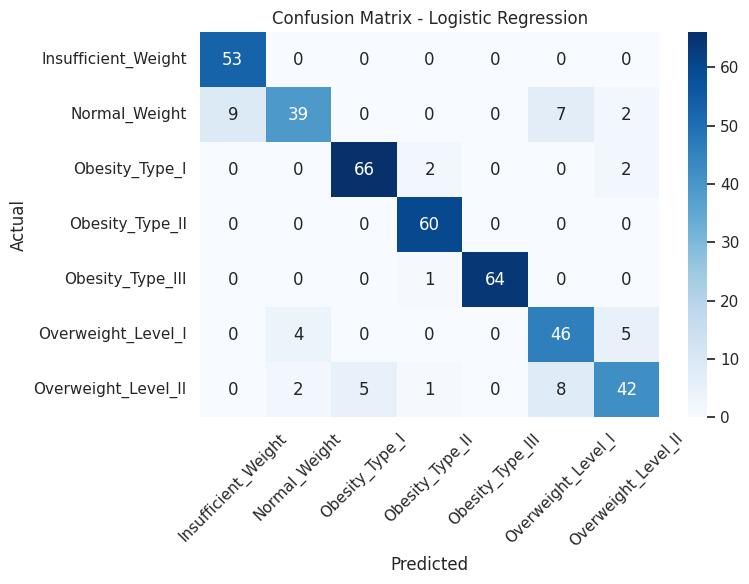

===== Decision Tree =====
Accuracy: 0.9354

Classification Report:
                     precision    recall  f1-score   support

Insufficient_Weight       0.98      0.92      0.95        53
      Normal_Weight       0.85      0.89      0.87        57
     Obesity_Type_I       0.94      0.94      0.94        70
    Obesity_Type_II       0.98      0.98      0.98        60
   Obesity_Type_III       1.00      0.98      0.99        65
 Overweight_Level_I       0.87      0.85      0.86        55
Overweight_Level_II       0.92      0.95      0.93        58

           accuracy                           0.94       418
          macro avg       0.93      0.93      0.93       418
       weighted avg       0.94      0.94      0.94       418



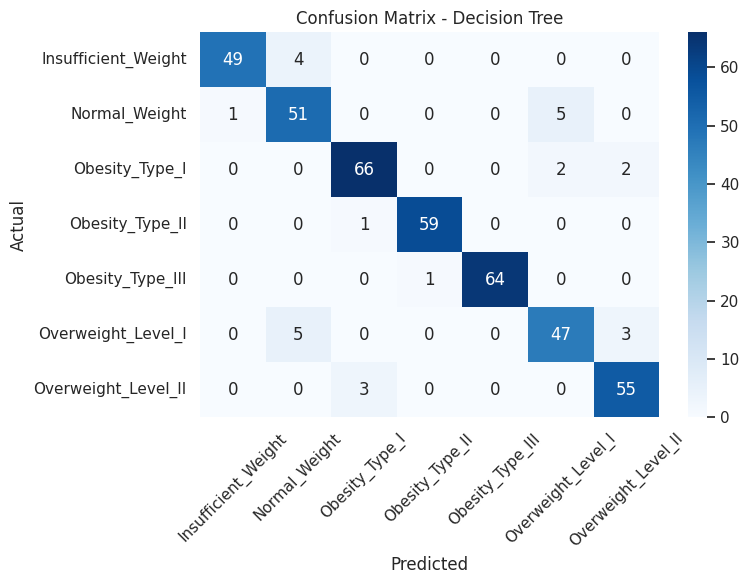

===== Random Forest =====
Accuracy: 0.9569

Classification Report:
                     precision    recall  f1-score   support

Insufficient_Weight       1.00      0.94      0.97        53
      Normal_Weight       0.83      0.96      0.89        57
     Obesity_Type_I       0.99      0.97      0.98        70
    Obesity_Type_II       1.00      1.00      1.00        60
   Obesity_Type_III       1.00      0.98      0.99        65
 Overweight_Level_I       0.92      0.89      0.91        55
Overweight_Level_II       0.96      0.93      0.95        58

           accuracy                           0.96       418
          macro avg       0.96      0.96      0.96       418
       weighted avg       0.96      0.96      0.96       418



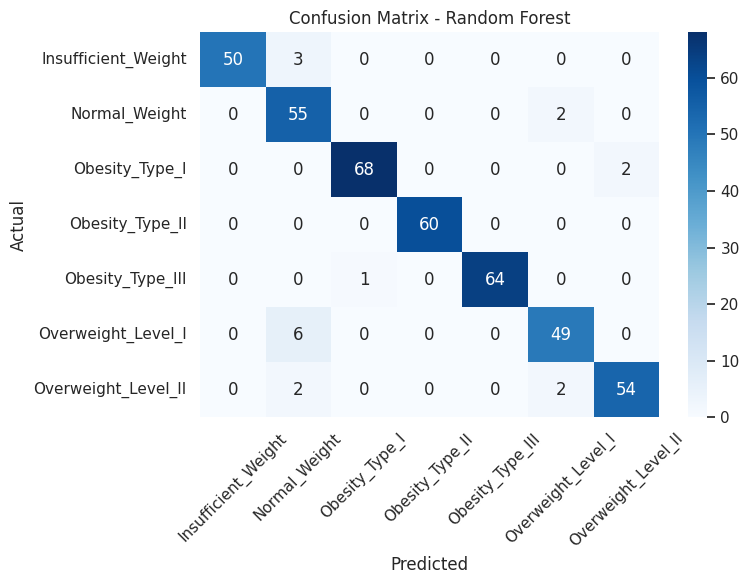

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import matplotlib.pyplot as plt
import seaborn as sns

# Use the original class names from the LabelEncoder
class_names = target_le.classes_  # e.g., ['Insufficient_Weight', 'Normal_Weight', ...]

# ----- Logistic Regression -----
print("===== Logistic Regression =====")
print("Accuracy: {:.4f}".format(accuracy_score(y_test, y_test_pred_logreg)))
print("\nClassification Report:")
print(classification_report(y_test, y_test_pred_logreg, target_names=class_names))

# Confusion matrix
cm_logreg = confusion_matrix(y_test, y_test_pred_logreg)
plt.figure(figsize=(8,6))
sns.heatmap(cm_logreg, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.title('Confusion Matrix - Logistic Regression')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# ----- Decision Tree -----
print("===== Decision Tree =====")
print("Accuracy: {:.4f}".format(accuracy_score(y_test, y_test_pred)))
print("\nClassification Report:")
print(classification_report(y_test, y_test_pred, target_names=class_names))

cm_dt = confusion_matrix(y_test, y_test_pred)
plt.figure(figsize=(8,6))
sns.heatmap(cm_dt, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.title('Confusion Matrix - Decision Tree')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# ----- Random Forest -----
print("===== Random Forest =====")
print("Accuracy: {:.4f}".format(accuracy_score(y_test, y_test_pred_rf)))
print("\nClassification Report:")
print(classification_report(y_test, y_test_pred_rf, target_names=class_names))

cm_rf = confusion_matrix(y_test, y_test_pred_rf)
plt.figure(figsize=(8,6))
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.title('Confusion Matrix - Random Forest')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Save the Models and Preprocessing Objects

In [ ]:
import joblib
import json

# Save the three models
joblib.dump(logreg_model, 'logistic_regression_model.pkl')
joblib.dump(dt_model, 'decision_tree_model.pkl')
joblib.dump(rf_model, 'random_forest_model.pkl')

# Save the StandardScaler
joblib.dump(scaler, 'scaler.pkl')

# Save the target LabelEncoder
joblib.dump(target_le, 'target_label_encoder.pkl')

# Save the feature names (X is your feature DataFrame before train-test split)
with open('feature_names.json', 'w') as f:
    json.dump(list(X.columns), f)

print("✅ All files have been saved to /content/")

✅ All files have been saved to /content/


Save the model to google drive for prototype use later


In [ ]:
from google.colab import drive
import os
import joblib
import json

drive.mount('/content/drive')

# choose save path
save_dir = '/content/drive/MyDrive/BMDS2003_Project_Models'
os.makedirs(save_dir, exist_ok=True)
print(f"Files will be saved to: {save_dir}")

# save 3 model
joblib.dump(logreg_model, f'{save_dir}/logistic_regression_model.pkl')
joblib.dump(dt_model, f'{save_dir}/decision_tree_model.pkl')
joblib.dump(rf_model, f'{save_dir}/random_forest_model.pkl')

# save preprocess object
joblib.dump(scaler, f'{save_dir}/scaler.pkl')
joblib.dump(target_le, f'{save_dir}/target_label_encoder.pkl')


with open(f'{save_dir}/feature_names.json', 'w') as f:
    json.dump(list(X.columns), f)

print("✅ All files have been saved directly to Google Drive!")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Files will be saved to: /content/drive/MyDrive/BMDS2003_Project_Models
✅ All files have been saved directly to Google Drive!
